# Learning over many decades: exact full-batch GD and ridge

**Julian Hoyer's extension** of the idealized ring-network experiment. This
notebook uses the already generated tuning curves and initial states, with
$\lambda=1$, no update noise, $\eta_0=0.5$ and float64 arithmetic. A row-wise SVD
gives the weights after $t$ full-batch gradient steps without performing those
steps. A short explicit loop is used **only to validate** that formula.

Run with **Python 3.12 (ring-repro)**. Existing executed outputs below contain the
results. All new files go to `notebooks/power_law_outputs/`; the source model,
its previous measurements, `ring/` and `data/` are read without modification.

### Adjustments agreed before execution

1. **Validation:** the previous checkpoints came from random minibatches of 50,
   whereas the closed form is deterministic full-batch GD. Formula correctness
   is checked against direct full-batch updates at steps 1, 2, 10, 30 and 100,
   with a relative weight tolerance of $10^{-9}$. Failure stops this notebook.
   The saved minibatch checkpoints are compared separately through 30,000 steps;
   drift differences above 10% are flagged, rather than used as a false test of
   the full-batch formula.
2. **Ridge:** $\lambda_{\rm ridge}=1/(\eta_0t)$ matches an approximate spectral
   cutoff. Ridge and early stopping have different filters and need not agree.
3. **Numerics:** use `-expm1(t * log1p(-eta0*a)) / s`, masking $s<10^{-12}$, to
   avoid cancellation at small eigenvalues and large $t$. Each row's SVD is
   reused at every requested time. The diagonal is explicitly kept at zero.
4. **Inference:** fit only the contiguous $t\ge10^3$ region before the first
   sampled GD drift at or below the paper level. Report the number of fit
   points and log-space $R^2$. A crossing may be absent; any crossing time
   interpolated between grid points is labeled an estimate, with its bracket.
   The finite-ridge paper reference is a comparison, not an assumed lower bound.
5. **Plotting:** positive quantities use log-log axes. Relative weight distance
   uses a symmetric log scale near zero so the paper's exact zero line is visible.
6. **Inputs:** arrays come from `model.npz`; settings come from the adjacent
   `config.json`. The three measurement functions are copied unchanged from
   `predictive_rule_preview/preview.ipynb`; callers pass only new output folders.

In [1]:
import hashlib
import json
import os
import platform
import sys
import time
from pathlib import Path

sys.dont_write_bytecode = True
os.environ.setdefault('CUBLAS_WORKSPACE_CONFIG', ':4096:8')
import numpy as np
import pandas as pd
import scipy
import scipy.linalg
import torch
from matplotlib.figure import Figure
from IPython.display import Image, Markdown, display
from threadpoolctl import threadpool_limits

HERE = Path.cwd().resolve()
SEARCH_ROOTS = [HERE, *HERE.parents]
CANDIDATES = SEARCH_ROOTS + [p / '.worktrees/local-learning' for p in SEARCH_ROOTS]
REPO_ROOT = next(p for p in CANDIDATES
                 if (p / 'ring/sim.py').is_file()
                 and (p / 'notebooks/predictive_rule_outputs/full/model.npz').is_file())
sys.path.insert(0, str(REPO_ROOT))
from ring import fn, regression, sim

SOURCE = REPO_ROOT / 'notebooks/predictive_rule_outputs/full'
OUT = REPO_ROOT / 'notebooks/power_law_outputs'
OUT.mkdir(parents=True, exist_ok=True)
config = json.loads((SOURCE / 'config.json').read_text())

def load_npz(path):
    with np.load(path, allow_pickle=False) as data:
        return {key: data[key].copy() for key in data.files}

model = load_npz(SOURCE / 'model.npz')
H, Phi = model['H'], model['Phi']
J_paper, x_init = model['J_paper'], model['x_init']
theta, theta_idx = model['theta'], model['theta_idx']
N, N_theta = config['N'], config['N_theta']
beta, eta0 = config['beta'], 0.5
tau, dt, T_TOTAL, T_EVAL = config['tau'], config['dt'], config['T_total'], config['T_eval']
N_INIT, ANGLE_TOL_DEG = config['n_init'], config['angle_tolerance_deg']
DEVICE, DTYPE = torch.device(config['device']), torch.float64
torch.set_num_threads(min(4, os.cpu_count() or 1))
torch.use_deterministic_algorithms(True)
STEPS = np.array([10, 30, 100, 300, 1000, 3000, 10000, 30000,
                  100000, 300000, 1000000, 10000000, 100000000, 1000000000], dtype=np.int64)
VALIDATION_STEPS = [1, 2, 10, 30, 100]
ALL_STEPS = np.unique(np.r_[STEPS, VALIDATION_STEPS])
STEP_INDEX = {int(t): i for i, t in enumerate(ALL_STEPS)}
S_MIN = 1e-12

def nonlin(x):
    return fn.nonlin_idealized(x, beta)

def as_tensor(x):
    return torch.as_tensor(x, dtype=DTYPE, device=DEVICE)

H_t, Phi_t = as_tensor(H), as_tensor(Phi)
J_paper_t = as_tensor(J_paper)
paper_norm = torch.linalg.vector_norm(J_paper_t)
start_deg = np.rad2deg(theta[theta_idx])
harmonic_projection = np.exp(1j * theta) @ Phi / (N * N_theta)
dc_projection = Phi.mean(axis=0) / N
assert H.shape == Phi.shape == (N_theta, N)
assert H.dtype == Phi.dtype == np.float64

def save_json(path, data):
    path.write_text(json.dumps(data, indent=2, allow_nan=False) + '\n')

def show_figure(fig, filename):
    path = OUT / filename
    fig.savefig(path, dpi=150)
    display(Image(filename=str(path)))

provenance = dict(
    source_config=config, eta0=eta0, requested_steps=STEPS.tolist(),
    all_cached_steps=ALL_STEPS.tolist(), singular_cutoff=S_MIN,
    model_sha256=hashlib.sha256((SOURCE / 'model.npz').read_bytes()).hexdigest(),
    python=platform.python_version(), numpy=np.__version__, scipy=scipy.__version__,
    torch=torch.__version__, measurement_source_sha256='2c679195eab7f4012566b00c4d0373bfc5c9586d9601e8e131ecebe173e63a7c',
)
provenance_path = OUT / 'experiment.json'
if provenance_path.exists() and json.loads(provenance_path.read_text()) != provenance:
    raise RuntimeError('Output configuration changed. Move power_law_outputs aside before rerunning.')
save_json(provenance_path, provenance)
print(f'{N} neurons, {N_theta} angles, {N_INIT} initial states; output: {OUT}')

1000 neurons, 500 angles, 34 initial states; output: /Users/julianhoyer/Documents/symmetries-continuous-attractors/.worktrees/local-learning/notebooks/power_law_outputs


## Unchanged measurement helpers

The following cell is copied verbatim from the preview notebook. In particular,
drift is measured over 0.5–1 s, final-angle clustering uses a 3-degree tolerance,
and the final input-off state is evaluated at exactly 30 s. Each call writes its
NPZ metrics under the new output directory. CSV summaries are generated below.

In [2]:
def decode_states(states):
    """Input (..., neurons, starts); return angle and relative first harmonic."""
    rates = nonlin(np.asarray(states))
    z = np.einsum('n,...nb->...b', harmonic_projection, rates)
    dc = np.einsum('n,...nb->...b', dc_projection, rates)
    strength = np.abs(z) / np.maximum(np.abs(dc), np.finfo(float).tiny)
    angle = np.angle(z)
    angle[(strength < 1e-10) | ~np.isfinite(strength)] = np.nan
    return angle, strength

def count_final_angles(angles, tolerance_deg=ANGLE_TOL_DEG):
    angles = np.asarray(angles)
    if not np.isfinite(angles).all():
        return np.nan
    values = np.sort(np.rad2deg(angles) % 360)
    if not len(values):
        return 0
    # A valid cluster is a circular arc of length <= tolerance; no chaining.
    extended = np.r_[values, values + 360]
    best = len(values)
    for cut in range(len(values)):
        clusters, end = 0, -np.inf
        for value in extended[cut:cut + len(values)]:
            if value > end + 1e-9:
                clusters += 1
                end = value + tolerance_deg
        best = min(best, clusters)
    return best

@torch.no_grad()
def measure(J, label, directory):
    directory.mkdir(parents=True, exist_ok=True)
    J_t = as_tensor(J)
    started = time.perf_counter()
    final_x, history, finished = sim.run_sim(
        T=T_TOTAL, tau=tau, dt=dt, T_eval=T_EVAL,
        J=J_t, x_init=as_tensor(x_init.copy()), nonlin=nonlin,
        break_if_stopped=False, disable_tqdm=True,
    )
    # run_sim performs int(T/dt)-1 updates: complete exactly T/dt updates.
    target_steps = int(round(T_TOTAL / dt))
    completed_steps = int(T_TOTAL / dt) - 1
    remaining = target_steps - completed_steps
    final_x, _, _ = sim.run_sim(
        T=(remaining + 1) * dt, tau=tau, dt=dt, T_eval=None,
        J=J_t, x_init=as_tensor(final_x.copy()), nonlin=nonlin,
        break_if_stopped=False, disable_tqdm=True,
    )
    times = np.arange(history.shape[0]) * T_EVAL
    # Decode in chunks to avoid allocating a second complete rate history.
    decoded = [decode_states(history[i:i + 16]) for i in range(0, len(history), 16)]
    angles = np.concatenate([item[0] for item in decoded])
    strength = np.concatenate([item[1] for item in decoded])
    final_angles, final_strength = decode_states(final_x)
    window = (times >= 0.5 - 1e-9) & (times <= 1.0 + 1e-9)
    window_times = times[window]
    assert len(window_times) >= 2
    assert np.isclose(window_times[0], 0.5) and np.isclose(window_times[-1], 1.0)
    window_angles = angles[window]
    valid_drift = np.isfinite(window_angles).all(axis=0)
    speeds = np.full(N_INIT, np.nan)
    net_drift = np.full(N_INIT, np.nan)
    if valid_drift.any():
        unwrapped = np.unwrap(window_angles[:, valid_drift], axis=0)
        increments = np.rad2deg(np.diff(unwrapped, axis=0))
        speeds[valid_drift] = np.abs(increments).sum(axis=0) / (window_times[-1] - window_times[0])
        net_drift[valid_drift] = np.rad2deg(unwrapped[-1] - unwrapped[0]) / (window_times[-1] - window_times[0])
    result = dict(
        label=label,
        flow_error=float(((-H_t + Phi_t @ J_t.T).square().mean().sqrt()).cpu()),
        drift_deg_s=float(np.mean(speeds[valid_drift])) if valid_drift.any() else np.nan,
        distinct_final=count_final_angles(final_angles),
        relative_weight_error=float((torch.linalg.vector_norm(J_t - J_paper_t) / paper_norm).cpu()),
        singular_values=torch.linalg.svdvals(J_t)[:12].cpu().numpy(),
        start_deg=start_deg.copy(), initial_angles=angles[0], final_angles=final_angles,
        drift_per_start_deg_s=speeds, net_drift_per_start_deg_s=net_drift,
        decoded_times=times, decoded_angles=angles, harmonic_strength=strength,
        final_harmonic_strength=final_strength, final_state=final_x,
        valid_drift_starts=int(valid_drift.sum()), valid_final_starts=int(np.isfinite(final_angles).sum()),
        evaluation_seconds=time.perf_counter() - started,
        final_time_s=target_steps * dt, simulation_finished=bool(finished),
    )
    np.savez_compressed(directory / 'metrics.npz', **result)
    return result

## A. Closed-form full-batch weights, with zero diagonal

With row $i$ initialized at zero and presynaptic coordinate $i$ excluded, let
$\Phi_i=U_i\operatorname{diag}(s_i)V_i^T$, where column $i$ of $\Phi_i$ is zero.
Then
\[
J_{t,i:}=(H_{:i}^TU_i)\operatorname{diag}\left[
\frac{1-(1-\eta_0s_i^2/(NN_\theta))^t}{s_i}\right]V_i^T.
\]
Excluding the coordinate is equivalent to setting the diagonal to zero after
each gradient update. Singular values below $10^{-12}$ contribute zero. The
spectral step size is checked to stay below 1, so this stable logarithmic filter
has a positive base. We cache the weight array in float64, with progress saved
every 25 rows, so rerunning does not repeat completed row decompositions.

In [3]:
with threadpool_limits(limits=4):
    gram_top = scipy.linalg.eigvalsh(Phi @ Phi.T / (N * N_theta),
                                   subset_by_index=[N_theta - 1, N_theta - 1], check_finite=False)[0]
if eta0 * gram_top >= 1:
    raise RuntimeError('This log-filter implementation requires eta0 * max(a) < 1.')
print(f'Upper bound for eta0*a across all excluded-neuron problems: {eta0 * gram_top:.6f}')

cache_path = OUT / 'closed_form_weights.npy'
progress_path = OUT / 'svd_progress.json'
cache_shape = (len(ALL_STEPS), N, N)
if cache_path.exists():
    if not progress_path.exists():
        raise RuntimeError('Weight cache has no progress record; move the incomplete cache aside.')
    weights = np.lib.format.open_memmap(cache_path, mode='r+')
    assert weights.shape == cache_shape and weights.dtype == np.float64
    first_row = json.loads(progress_path.read_text())['next_row']
else:
    weights = np.lib.format.open_memmap(cache_path, mode='w+', dtype=np.float64, shape=cache_shape)
    first_row = 0
    save_json(progress_path, dict(next_row=0, total_rows=N))

started = time.perf_counter()
with threadpool_limits(limits=4):
    for i in range(first_row, N):
        design = Phi.copy()
        design[:, i] = 0
        U, s, Vt = scipy.linalg.svd(design, full_matrices=False, check_finite=False)
        valid = s >= S_MIN
        a = s[valid] ** 2 / (N * N_theta)
        filters = np.zeros((len(ALL_STEPS), len(s)), dtype=np.float64)
        filters[:, valid] = -np.expm1(ALL_STEPS[:, None] * np.log1p(-eta0 * a)[None, :]) / s[valid]
        row_weights = ((H[:, i] @ U)[None, :] * filters) @ Vt
        row_weights[:, i] = 0
        weights[:, i, :] = row_weights
        if (i + 1) % 25 == 0 or i + 1 == N:
            weights.flush()
            save_json(progress_path, dict(next_row=i + 1, total_rows=N))
            if (i + 1) % 100 == 0 or i + 1 == N:
                print(f'SVD rows {i + 1}/{N}; elapsed {time.perf_counter() - started:.1f} s', flush=True)
assert np.isfinite(weights).all()
assert np.all(np.diagonal(weights, axis1=1, axis2=2) == 0)
print('Float64 closed-form weights ready for all requested times.')

Upper bound for eta0*a across all excluded-neuron problems: 0.581621


SVD rows 100/1000; elapsed 6.6 s


SVD rows 200/1000; elapsed 13.5 s


SVD rows 300/1000; elapsed 19.8 s


SVD rows 400/1000; elapsed 26.3 s


SVD rows 500/1000; elapsed 32.5 s


... (2 outputs left out)

SVD rows 800/1000; elapsed 51.0 s


SVD rows 900/1000; elapsed 57.2 s


SVD rows 1000/1000; elapsed 63.5 s


Float64 closed-form weights ready for all requested times.


## B1. Correctness validation against direct full-batch GD

This is the only training loop in the notebook: 100 full-batch steps solely to
check the formula. It uses exactly the N-normalized update and zeroes the
diagonal after every step. Relative Frobenius error above 1e-9 stops execution
before long-horizon measurements or ridge comparisons.

In [4]:
direct = torch.zeros((N, N), dtype=DTYPE, device=DEVICE)
validation_rows = []
with torch.no_grad():
    for step in range(1, max(VALIDATION_STEPS) + 1):
        direct.add_((H_t.T - direct @ Phi_t.T) @ Phi_t, alpha=eta0 / (N * N_theta))
        direct.fill_diagonal_(0)
        if step in VALIDATION_STEPS:
            closed = as_tensor(np.array(weights[STEP_INDEX[step]], copy=True))
            relative = float((torch.linalg.vector_norm(direct - closed) /
                              torch.linalg.vector_norm(direct)).cpu())
            max_abs = float((direct - closed).abs().max().cpu())
            validation_rows.append(dict(step=step, relative_frobenius_difference=relative,
                                        maximum_absolute_difference=max_abs))
validation_table = pd.DataFrame(validation_rows)
validation_table.to_csv(OUT / 'full_batch_validation.csv', index=False)
display(validation_table)
if not (validation_table['relative_frobenius_difference'] < 1e-9).all():
    raise RuntimeError('Closed-form/full-batch validation failed. Stopping before further measurements.')
del direct, closed
print('PASS: closed form matches explicit full-batch GD.')

,step,relative_frobenius_difference,maximum_absolute_difference
0,1,5.917025e-15,3.073713e-17
1,2,5.329340e-15,4.293441e-17
2,10,3.745688e-15,5.898060e-17
3,30,3.701783e-15,1.118897e-16
4,100,3.482350e-15,1.613293e-16


PASS: closed form matches explicit full-batch GD.


## B2. Comparison with the saved stochastic minibatch checkpoints

We report the relative Frobenius difference using the saved minibatch norm as
denominator. Both networks use the same input-off measurements. Drift differences
above 10% are labeled; they are not a failure of the full-batch formula, because
the saved weights followed different, stochastic updates. No existing metrics
are rewritten: newly evaluated saved weights, if needed, are written here.

In [5]:
gd_results = {}
minibatch_results = {}
comparison_rows = []

def measured_or_cached(J, method, step):
    folder = OUT / method / f'step_{int(step):010d}'
    metrics = folder / 'metrics.npz'
    if metrics.exists():
        return load_npz(metrics)
    return measure(J, f'{method}, t={int(step)}', folder)

for path in sorted((SOURCE / 'lam_1_noise_0').glob('step_*/weights.npz')):
    step = int(path.parent.name.split('_')[1])
    if step not in STEP_INDEX:
        continue
    saved = load_npz(path)['J']
    closed = np.array(weights[STEP_INDEX[step]], copy=True)
    gd = measured_or_cached(closed, 'closed_form_gd', step)
    gd_results[step] = gd
    old_metrics = path.parent / 'metrics.npz'
    minibatch = load_npz(old_metrics) if old_metrics.exists() else measured_or_cached(saved, 'saved_minibatch', step)
    minibatch_results[step] = minibatch
    drift_difference = abs(float(gd['drift_deg_s']) - float(minibatch['drift_deg_s'])) / max(abs(float(minibatch['drift_deg_s'])), np.finfo(float).tiny)
    comparison_rows.append(dict(
        step=step, relative_frobenius_difference=np.linalg.norm(closed - saved) / np.linalg.norm(saved),
        full_batch_drift_deg_s=float(gd['drift_deg_s']), minibatch_drift_deg_s=float(minibatch['drift_deg_s']),
        relative_drift_difference=drift_difference, drift_difference_over_10pct=drift_difference > .1,
        full_batch_distinct_final=float(gd['distinct_final']), minibatch_distinct_final=float(minibatch['distinct_final']),
    ))
comparison_table = pd.DataFrame(comparison_rows)
comparison_table.to_csv(OUT / 'minibatch_comparison.csv', index=False)
display(comparison_table)

,step,relative_frobenius_difference,full_batch_drift_deg_s,minibatch_drift_deg_s,relative_drift_difference,drift_difference_over_10pct,full_batch_distinct_final,minibatch_distinct_final
0,10,0.077787,61.126744,111.260564,0.450598,True,1.0,1.0
1,30,0.033181,17.450010,22.484971,0.223926,True,2.0,2.0
2,100,0.016180,6.810235,6.448768,0.056052,False,7.0,7.0
3,300,0.008337,3.932190,3.908556,0.006047,False,8.0,8.0
4,1000,0.004814,2.433896,2.416476,0.007209,False,11.0,12.0
5,3000,0.003009,1.800201,1.771506,0.016198,False,13.0,13.0
6,10000,0.001888,0.956700,0.950227,0.006811,False,18.0,19.0
7,30000,0.001217,0.505992,0.512650,0.012988,False,23.0,23.0


## C. Input-off dynamics of every closed-form GD matrix

Each requested t represents a number of deterministic gradient updates, not
elapsed physical time or a number of complete stochastic training epochs.
Every measurement still follows 30 seconds of physical input-off dynamics.

In [6]:
for t in STEPS:
    t = int(t)
    if t not in gd_results:
        print(f'Measuring closed-form GD: t={t:,}', flush=True)
        gd_results[t] = measured_or_cached(np.array(weights[STEP_INDEX[t]], copy=True), 'closed_form_gd', t)

paper_path = SOURCE / 'J_paper/metrics.npz'
paper_result = load_npz(paper_path) if paper_path.exists() else measured_or_cached(J_paper, 'paper_reference', 0)

Measuring closed-form GD: t=100,000


Measuring closed-form GD: t=300,000


Measuring closed-form GD: t=1,000,000


Measuring closed-form GD: t=10,000,000


Measuring closed-form GD: t=100,000,000


Measuring closed-form GD: t=1,000,000,000


## D. Ridge at the matching approximate cutoff

For each t use `regression.compute_J(H, Phi, lamda=1/(eta0*t))`, including its
zero-diagonal correction. The eigenmode filters differ:
\[
f_{\rm GD}(a,t)=1-(1-\eta_0a)^t,\qquad
f_{\rm ridge}(a,t)=\frac{a}{a+1/(\eta_0t)}.
\]
Thus this comparison tests a regularization analogy, rather than an identity.
The paper reference itself has ridge coefficient $10^{-8}$; at the largest t,
the comparison ridge coefficient is smaller than that value.

In [7]:
ridge_results = {}
for t in STEPS:
    t = int(t)
    metrics = OUT / 'ridge' / f'step_{t:010d}' / 'metrics.npz'
    if metrics.exists():
        ridge_results[t] = load_npz(metrics)
        continue
    ridge_lambda = 1.0 / (eta0 * t)
    print(f'Measuring ridge: t={t:,}, lambda={ridge_lambda:.5g}', flush=True)
    with threadpool_limits(limits=4):
        J_ridge, _ = regression.compute_J(H, Phi, ridge_lambda)
    ridge_results[t] = measured_or_cached(J_ridge, 'ridge', t)

Measuring ridge: t=10, lambda=0.2


Measuring ridge: t=30, lambda=0.066667


Measuring ridge: t=100, lambda=0.02


Measuring ridge: t=300, lambda=0.0066667


Measuring ridge: t=1,000, lambda=0.002


Measuring ridge: t=3,000, lambda=0.00066667


... (4 outputs left out)

Measuring ridge: t=1,000,000, lambda=2e-06


Measuring ridge: t=10,000,000, lambda=2e-07


Measuring ridge: t=100,000,000, lambda=2e-08


Measuring ridge: t=1,000,000,000, lambda=2e-09


## E. Metric tables and power-law fit

Fit log(drift) against log(t) over the contiguous GD grid starting at t = 1,000
and ending before its first sampled point at or below the paper-reference drift.
The fitted exponent p means drift is proportional to t**p within that window;
it is not assumed to hold outside the fitted interval. The reported R-squared
describes log-space fit quality, not statistical uncertainty across networks.

Crossing estimates use log-log interpolation between adjacent measured points.
Both the first crossing of the paper level and of twice that level are reported,
with their measured brackets. If not reached by 1e9, say so rather than extrapolate.

In [8]:
METRICS = ['drift_deg_s', 'distinct_final', 'flow_error', 'relative_weight_error']
rows = []
for method, results in [('closed_form_gd', gd_results), ('ridge', ridge_results), ('saved_minibatch', minibatch_results)]:
    for t, result in sorted(results.items()):
        rows.append(dict(method=method, step=t, ridge_lambda=1/(eta0*t) if method == 'ridge' else np.nan,
                         **{key: float(result[key]) for key in METRICS},
                         valid_drift_starts=int(result['valid_drift_starts']),
                         valid_final_starts=int(result['valid_final_starts'])))
metric_table = pd.DataFrame(rows)
metric_table.to_csv(OUT / 'metrics.csv', index=False)
pd.DataFrame([dict(method='J_paper', **{key: float(paper_result[key]) for key in METRICS})]).to_csv(OUT / 'paper_reference.csv', index=False)
display(metric_table)

paper_drift = float(paper_result['drift_deg_s'])
drifts = np.array([float(gd_results[int(t)]['drift_deg_s']) for t in STEPS])
fit_mask = STEPS >= 1000
reached = np.flatnonzero(np.isfinite(drifts) & (drifts <= paper_drift))
if len(reached):
    fit_mask &= np.arange(len(STEPS)) < reached[0]
fit_mask &= np.isfinite(drifts) & (drifts > 0)
fit = dict(points=int(fit_mask.sum()), paper_drift_deg_s=paper_drift,
           exponent=None, log_space_r_squared=None, fit_start_step=None, fit_end_step=None, prefactor=None)
if fit_mask.sum() >= 3:
    x, y = np.log(STEPS[fit_mask].astype(float)), np.log(drifts[fit_mask])
    exponent, intercept = np.polyfit(x, y, 1)
    residual = np.sum((y - (intercept + exponent*x))**2)
    total = np.sum((y-y.mean())**2)
    fit.update(exponent=float(exponent), log_space_r_squared=float(1-residual/total) if total > 0 else None,
               fit_start_step=int(STEPS[fit_mask][0]), fit_end_step=int(STEPS[fit_mask][-1]), prefactor=float(np.exp(intercept)))
    print(f'Drift ~ t^{exponent:.5f}; log-space R^2={fit["log_space_r_squared"]:.5f}; '
          f'{fit["points"]} grid points, t={fit["fit_start_step"]:,} to {fit["fit_end_step"]:,}.')
else:
    print('Insufficient positive pre-reference grid points for a power-law fit.')

def crossing(threshold):
    for i, value in enumerate(drifts):
        if not np.isfinite(value):
            continue
        if value <= threshold:
            if i == 0:
                return dict(status='at or before first grid point', threshold_deg_s=threshold,
                            lower_step=None, upper_step=int(STEPS[0]), estimated_step=None)
            previous = drifts[i-1]
            if not np.isfinite(previous) or previous <= threshold:
                return dict(status='crossing bracket unavailable', threshold_deg_s=threshold,
                            lower_step=None, upper_step=int(STEPS[i]), estimated_step=None)
            if value > 0:
                fraction = (np.log(threshold)-np.log(previous))/(np.log(value)-np.log(previous))
                estimate = np.exp(np.log(float(STEPS[i-1])) + fraction*np.log(float(STEPS[i])/STEPS[i-1]))
            else:
                estimate = None
            return dict(status='observed bracket; log-log interpolation', threshold_deg_s=threshold,
                        lower_step=int(STEPS[i-1]), upper_step=int(STEPS[i]),
                        estimated_step=float(estimate) if estimate is not None else None)
    return dict(status='not observed through 1e9 steps', threshold_deg_s=threshold,
                lower_step=None, upper_step=None, estimated_step=None)

crossings = {name: crossing(multiplier*paper_drift) for name, multiplier in [('paper',1), ('twice_paper',2)]}
for name, result in crossings.items():
    print(name, result)
save_json(OUT / 'power_law_fit.json', fit)
save_json(OUT / 'crossings.json', crossings)
pd.DataFrame([fit]).to_csv(OUT / 'power_law_fit.csv', index=False)
pd.DataFrame([dict(level=name, **result) for name, result in crossings.items()]).to_csv(OUT / 'crossings.csv', index=False)

,method,step,ridge_lambda,drift_deg_s,distinct_final,flow_error,relative_weight_error,valid_drift_starts,valid_final_starts
0,closed_form_gd,10,NaN,61.126744,1.0,0.491079,0.726247,34,34
1,closed_form_gd,30,NaN,17.450010,2.0,0.238916,0.525726,34,34
2,closed_form_gd,100,NaN,6.810235,7.0,0.087538,0.354294,34,34
3,closed_form_gd,300,NaN,3.932190,8.0,0.027942,0.269459,34,34
4,closed_form_gd,1000,NaN,2.433896,11.0,0.007768,0.240126,34,34
5,closed_form_gd,3000,NaN,1.800201,13.0,0.003969,0.227646,34,34
6,closed_form_gd,10000,NaN,0.956700,18.0,0.002056,0.215299,34,34
7,closed_form_gd,30000,NaN,0.505992,23.0,0.001290,0.203097,34,34
8,closed_form_gd,100000,NaN,0.335403,22.0,0.000809,0.184560,34,34
9,closed_form_gd,300000,NaN,0.212903,27.0,0.000464,0.163096,34,34


Drift ~ t^-0.42758; log-space R^2=0.99598; 8 grid points, t=1,000 to 10,000,000.
paper {'status': 'observed bracket; log-log interpolation', 'threshold_deg_s': 0.023253161361236133, 'lower_step': 10000000, 'upper_step': 100000000, 'estimated_step': 88455933.17292835}
twice_paper {'status': 'observed bracket; log-log interpolation', 'threshold_deg_s': 0.046506322722472265, 'lower_step': 10000000, 'upper_step': 100000000, 'estimated_step': 12283819.671433961}


## Learning curves over eight decades

Solid curves are deterministic full-batch GD and ridge. Cross markers are the
original stochastic minibatch checkpoints. The dashed black line is J_paper.
The drift fit is drawn only over the points used to fit it; it is not extrapolated.
Distinct-angle counts are discrete, tolerance-dependent outcomes, not a count
of mathematically established fixed points.

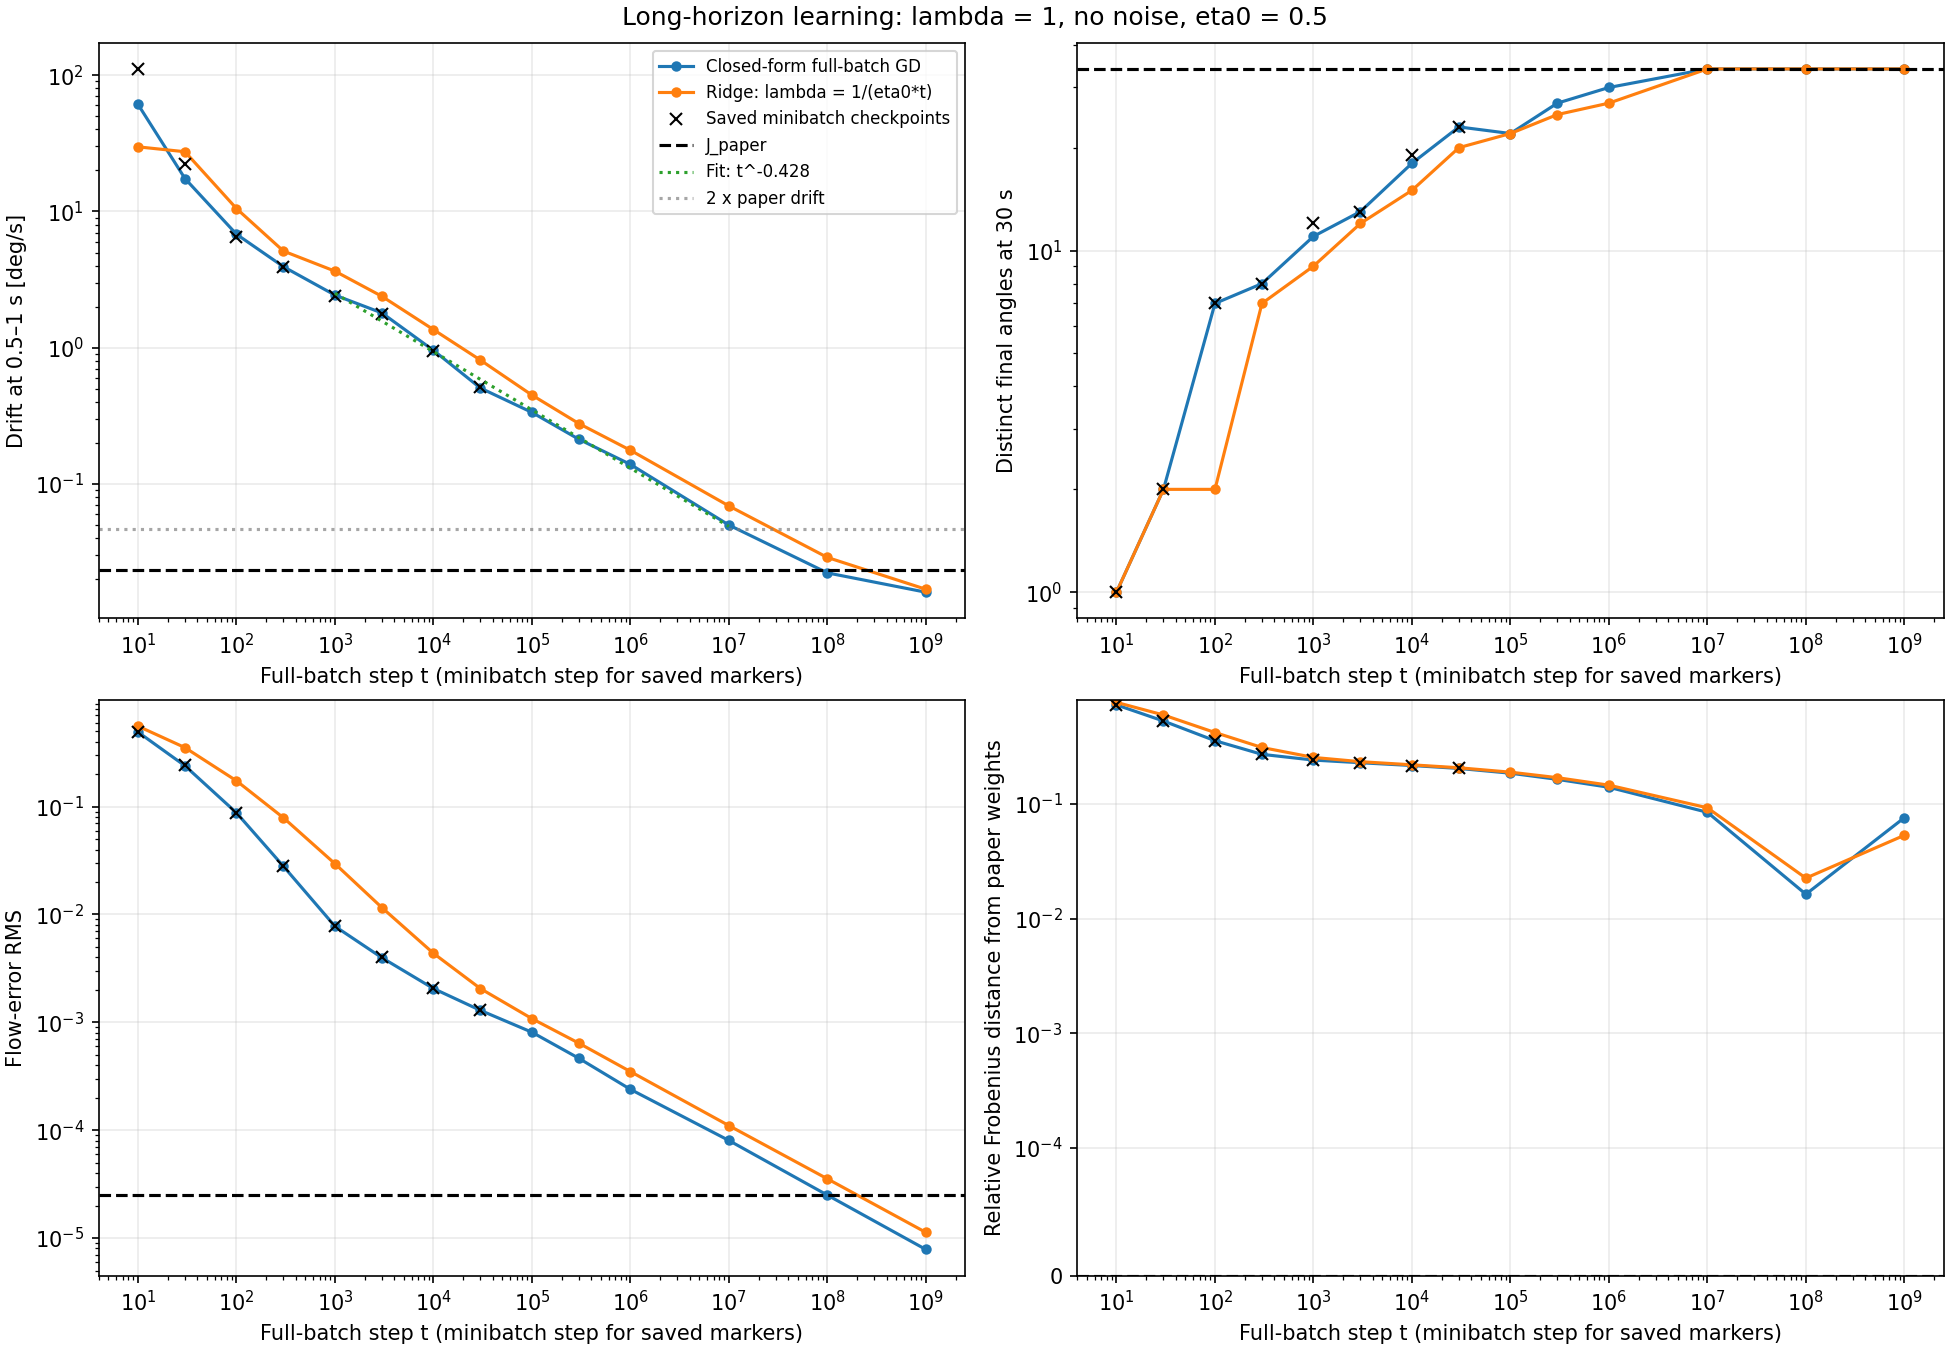

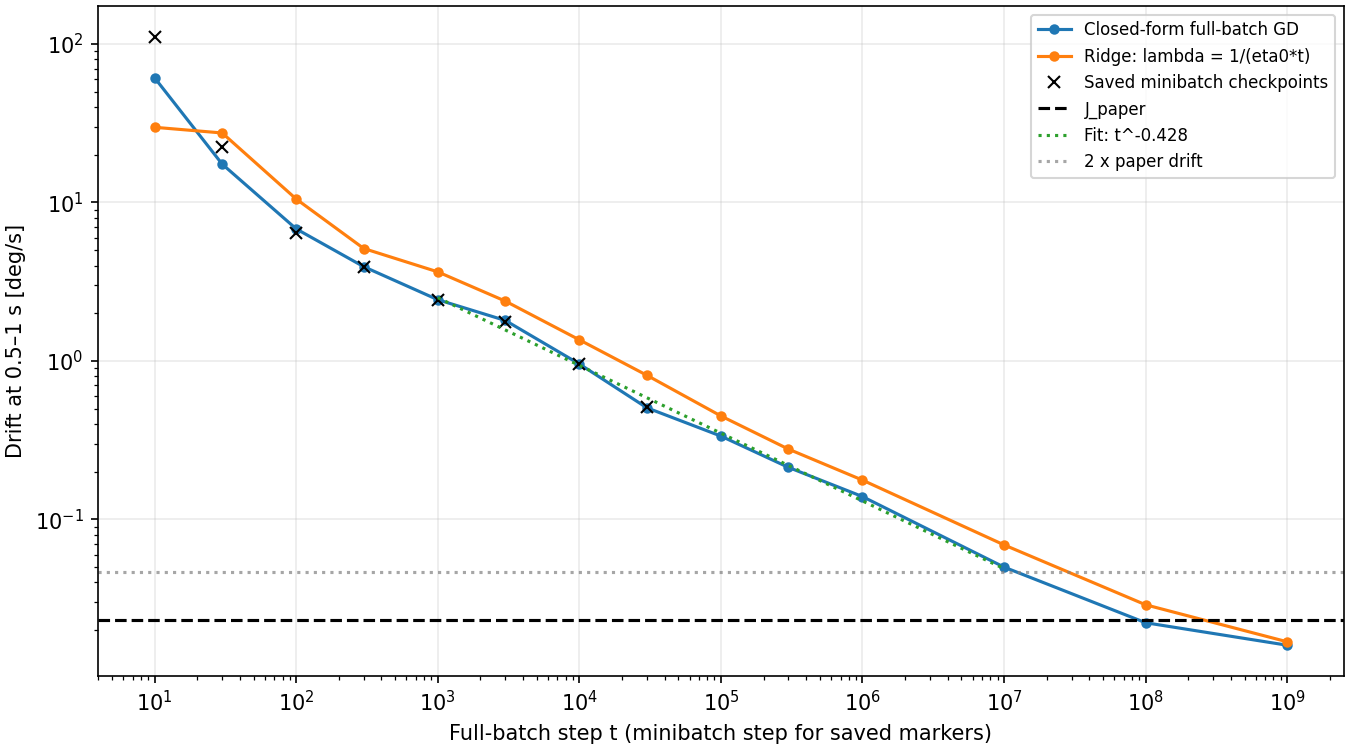

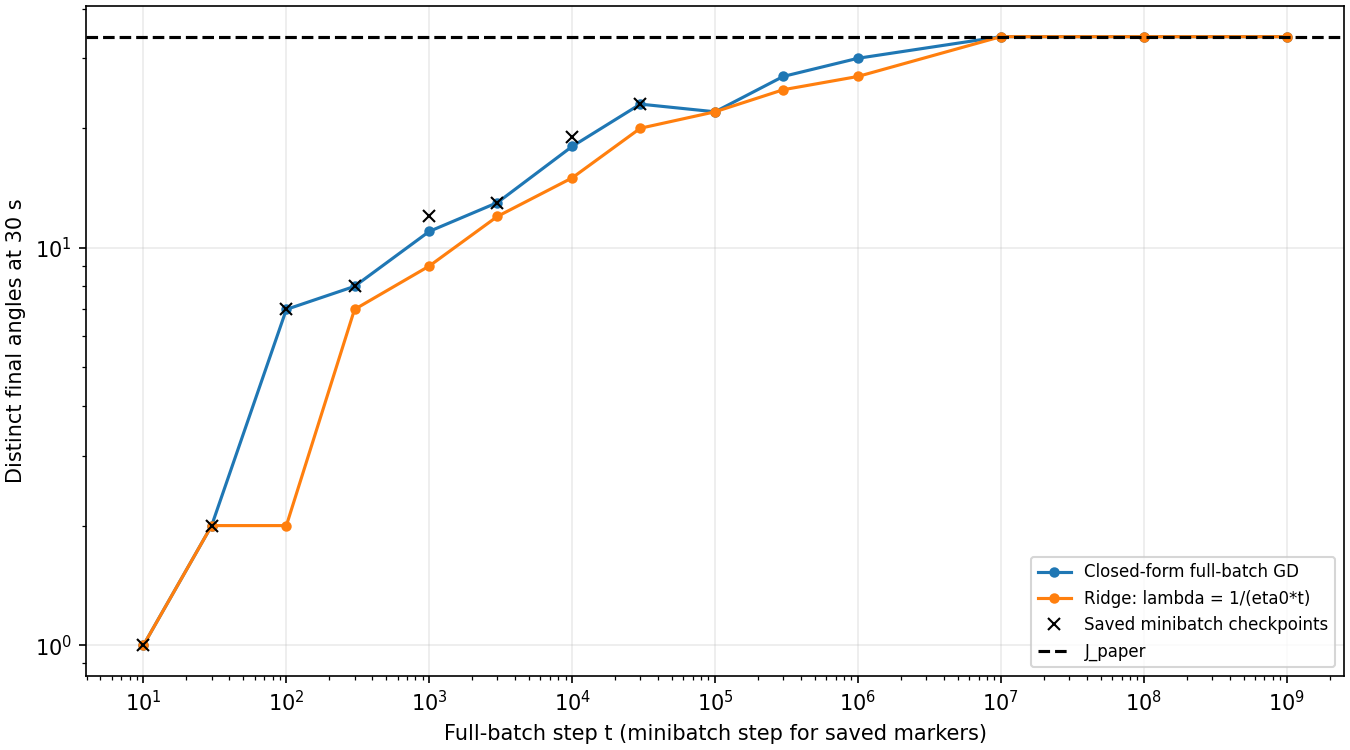

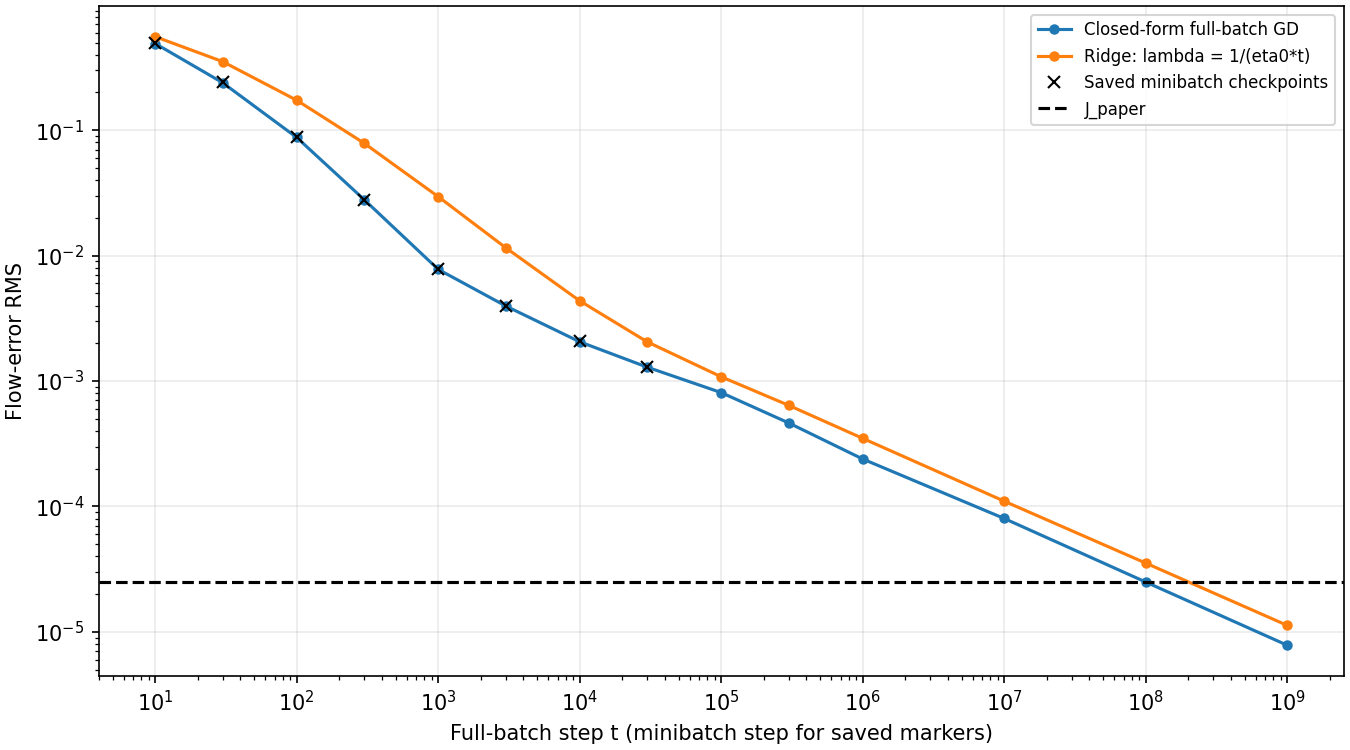

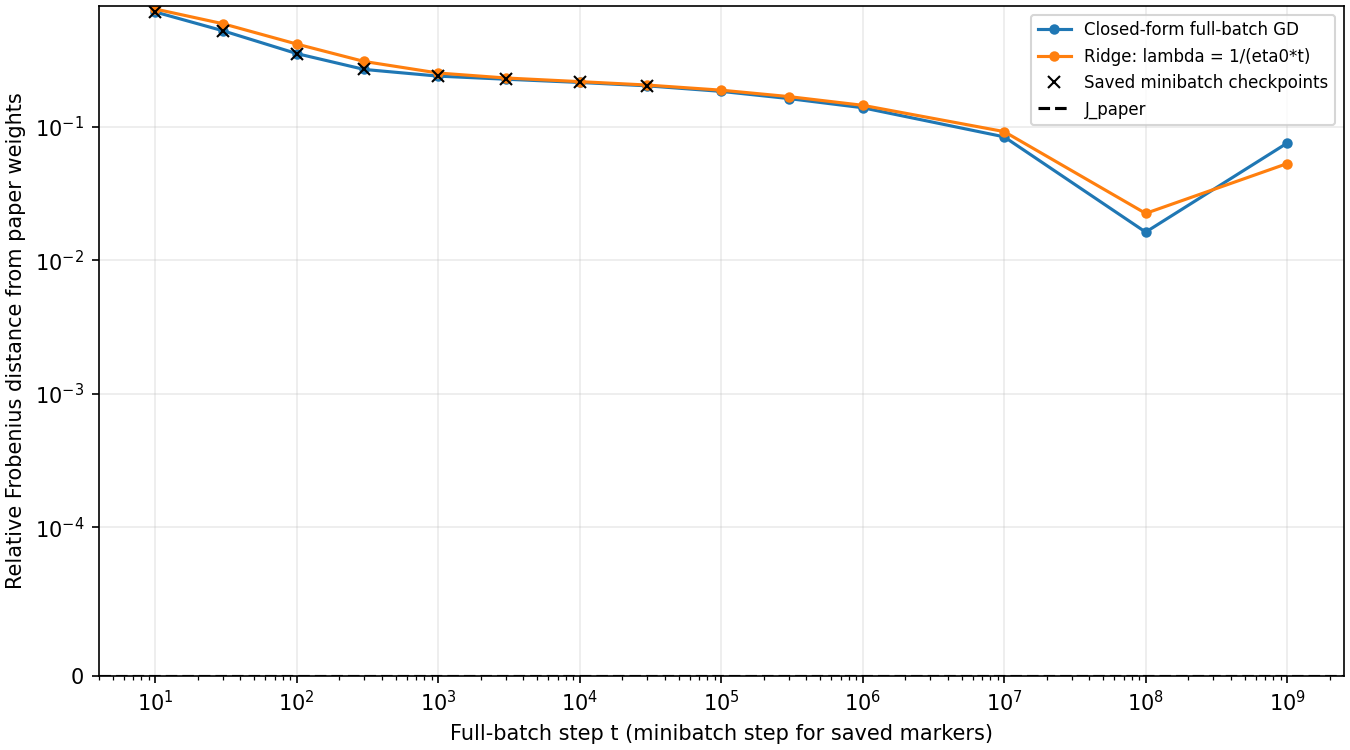

In [9]:
LABELS = ['Drift at 0.5–1 s [deg/s]', 'Distinct final angles at 30 s',
          'Flow-error RMS', 'Relative Frobenius distance from paper weights']

def plot_metric(ax, metric, ylabel):
    for label, results, color in [('Closed-form full-batch GD', gd_results, 'tab:blue'),
                                   ('Ridge: lambda = 1/(eta0*t)', ridge_results, 'tab:orange')]:
        ax.plot(STEPS, [float(results[int(t)][metric]) for t in STEPS], 'o-', label=label, color=color, ms=4)
    saved_steps = sorted(minibatch_results)
    ax.plot(saved_steps, [float(minibatch_results[t][metric]) for t in saved_steps],
            'kx', label='Saved minibatch checkpoints', ms=6)
    ax.axhline(float(paper_result[metric]), color='black', ls='--', label='J_paper')
    if metric == 'drift_deg_s' and fit['exponent'] is not None:
        fit_steps = STEPS[fit_mask]
        ax.plot(fit_steps, fit['prefactor'] * fit_steps.astype(float)**fit['exponent'],
                ':', color='tab:green', label=f'Fit: t^{fit["exponent"]:.3f}')
        ax.axhline(2*paper_drift, color='gray', ls=':', alpha=.7, label='2 x paper drift')
    ax.set_xscale('log')
    if metric == 'relative_weight_error':
        ax.set_yscale('symlog', linthresh=1e-4)
        ax.set_ylim(bottom=0)
    else:
        ax.set_yscale('log')
    ax.set(xlabel='Full-batch step t (minibatch step for saved markers)', ylabel=ylabel)
    ax.grid(alpha=.25)

fig = Figure(figsize=(13, 9), layout='constrained')
axes = fig.subplots(2, 2)
for ax, metric, label in zip(axes.flat, METRICS, LABELS):
    plot_metric(ax, metric, label)
axes[0,0].legend(fontsize=8)
fig.suptitle('Long-horizon learning: lambda = 1, no noise, eta0 = 0.5')
show_figure(fig, 'power_law_metrics.png')

for metric, label in zip(METRICS, LABELS):
    individual = Figure(figsize=(9, 5), layout='constrained')
    ax = individual.subplots()
    plot_metric(ax, metric, label)
    ax.legend(fontsize=8)
    show_figure(individual, f'{metric}.png')

## Reuse and limits

`metrics.csv` contains the requested scalar results for GD, ridge and saved
minibatch checkpoints. Validation, paper-reference, crossing and fit tables are
separate CSV files. PNG figures, the float64 weight cache, SVD progress and the
unchanged measurement helper's per-checkpoint NPZ files are kept in the new
ignored output directory.

Rerunning reuses the recorded SVD progress and previously measured matrices.
These are deterministic full-batch and ridge comparisons for one tuning-curve
draw, with a fixed finite-time decoder. A good log-space fit is evidence about
this measured interval, not a universal exponent or proof of continuous-attractor
stability. Near or below the reference drift, numerical precision, finite-size
effects and the chosen measurement interval can all affect interpretation.